# 06 - Reconstruction methods (milestone 7)

`PROJECT_PLAN.md` §8: the GEVD-based multi-channel Wiener filter (Somers et
al. 2018), frontal-reference ridge regression (ocular), learned spatial
interpolation (muscle, pops) and the router that sends each detector class
to its method. All settings in `configs/reconstruction.yaml` are starting
values, tuned on Section A Set A at milestone 9.

Here: the rank-1 validation of the MWF (plan §4), then an oracle-flag check
on a Set A Dataset III recording (`adr.reconstruction.check`, also
`scripts/11_reconstruction_check.py`).

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from adr.config import load_paths, package_versions, seed_everything

logging.basicConfig(level=logging.INFO, format="%(message)s", force=True)
pd.set_option("display.max_columns", 50, "display.width", 200)
paths = load_paths()
seed_everything()
package_versions()

{'python': '3.14.8',
 'numpy': '2.5.4',
 'scipy': '1.18.1',
 'pandas': '3.0.6',
 'mne': '1.13.2',
 'scikit-learn': '1.9.1',
 'lightgbm': '4.7.0',
 'xgboost': '3.4.2',
 'eelbrain': '0.43.0b0',
 'matplotlib': '3.11.2',
 'mne-icalabel': '0.10.0'}

rank-1 test: kept rank 9, top generalized eigenvalues [1.8545e+03 1.2000e+00 1.2000e+00 1.1000e+00]
relative error on flagged samples: 4.29 -> 0.13


Text(0.5, 1.0, 'MWF on a known rank-1 artifact')

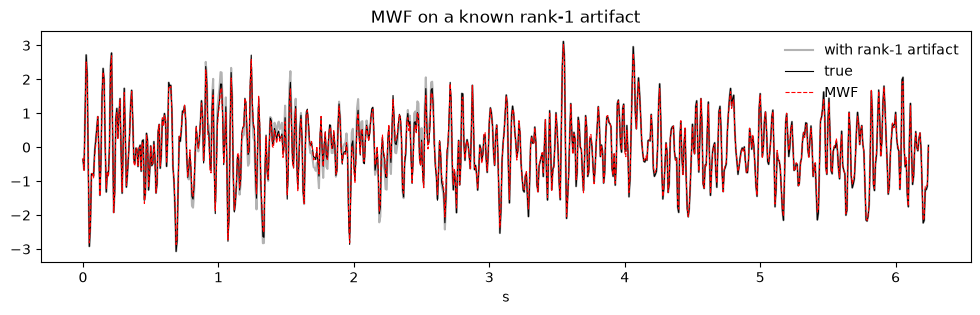

In [2]:
import scipy.signal
from adr.reconstruction import mwf, router
from adr.reconstruction import check

FS = 128.0
rng = np.random.default_rng(0)
n, c = int(FS * 120), 16
b, a = scipy.signal.butter(2, 30, fs=FS)
neural = scipy.signal.lfilter(b, a, rng.standard_normal((n, c)), axis=0) @ (rng.standard_normal((c, c)) * 0.3 + np.eye(c))
mask = np.zeros(n, bool)
for start in range(500, n - 300, 1500):
    mask[start:start + 250] = True
v = rng.standard_normal(c)
y = neural + np.outer(np.where(mask, 8 * np.sin(2 * np.pi * 2 * np.arange(n) / FS), 0), v)
model = mwf.fit(y, mask)
cleaned = model.clean(y)
before = np.linalg.norm((y - neural)[mask]) / np.linalg.norm(neural[mask])
after = np.linalg.norm((cleaned - neural)[mask]) / np.linalg.norm(neural[mask])
print(f"rank-1 test: kept rank {model.rank}, top generalized eigenvalues {np.round(model.eigenvalues[:4], 1)}")
print(f"relative error on flagged samples: {before:.2f} -> {after:.2f}")
t = np.arange(800) / FS
plt.figure(figsize=(12, 3))
plt.plot(t, y[400:1200, 0], color="0.7", label="with rank-1 artifact")
plt.plot(t, neural[400:1200, 0], "k", lw=0.8, label="true")
plt.plot(t, cleaned[400:1200, 0], "r--", lw=0.8, label="MWF")
plt.legend(frameon=False); plt.xlabel("s"); plt.title("MWF on a known rank-1 artifact")

## Oracle-flag check on Dataset III

Set A noise subject, -10 dB SNR, phantom Set A templates, one artifact type
at a time, true (injection-log) flags. Relative RMS error against the clean
synthetic EEG over the flagged samples; the `_excl_native` columns leave out
native transients of the "clean" Dataset I base (open item 13).

In [3]:
RUN_CHECK = False
table = (pd.concat([check.run(sar_db=s) for s in (0, -10)]) if RUN_CHECK
         else pd.read_csv(paths["results"] / "section_a" / "reconstruction_check.csv"))
table.pivot_table(index=["sar_db", "type"], columns="pipeline",
                  values=["rrmse_analysis_flagged_excl_native", "rrmse_broadband_flagged_excl_native"]).round(3)

rrmse_analysis_flagged_excl_native                                                 rrmse_broadband_flagged_excl_native                                                
pipeline                           no correction routed (oracle flags) single MWF (oracle flags)                       no correction routed (oracle flags) single MWF (oracle flags)
sar_db type                                                                                                                                                                         
-10    motion                              4.912                 0.582                     0.582                               2.612                 0.363                     0.363
       muscle                              2.018                 0.581                     0.571                               2.053                 0.571                     0.537
       ocular                              5.245                 0.753                     0.687                               2.169                 0.721                     0.542
       pop                                 0.290                 0.151                     0.332                               0.258                 0.135                     0.308
 0     motion                              1.553                 0.540                     0.540                               0.826                 0.312                     0.312
       muscle                              0.638                 0.529                     0.518                               0.649                 0.530                     0.491
       ocular                              1.659                 0.716                     0.668                               0.686                 0.697                     0.501
       pop                                 0.092                 0.147                     0.173                               0.082                 0.128                     0.193

## What each method does to one event

-10 dB SAR, one example event per artifact type (Fp1 for ocular, the
affected channel for pops, T7 otherwise).

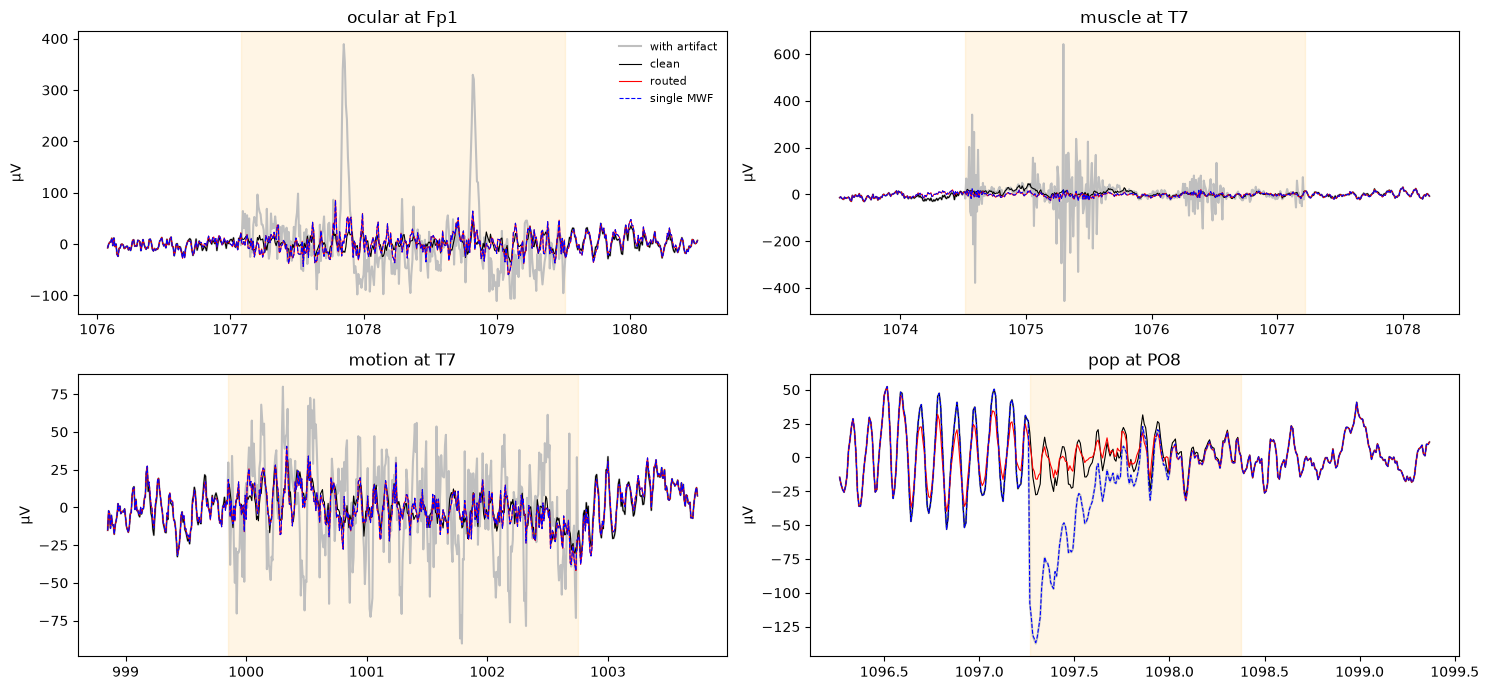

In [4]:
from adr.synth import dataset3 as d3, inject as I, templates as T
base, lags, _ = d3.load_base_trfs()
rec = d3.synthesize(d3.noise_source(d3.load_noise_split()["set_a"][0]), "L", -10, base, lags)
bank = T.load_bank("phantom_set_a_templates")
names = list(rec.ch_names)
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
for ax, kind in zip(axes.ravel(), I.TYPES):
    inj = I.inject(rec.eeg, FS, kind, -10, np.random.default_rng(3), bank=bank, ch_names=names)
    truth = I.window_truth(inj.log, len(rec.eeg), FS, 1.0, 0.5)
    starts = truth["start"].to_numpy()
    flags = {c: (truth[c].to_numpy() if c == kind else np.zeros(len(truth), bool)) for c in router.CLASSES}
    m = router.mask_from_windows(truth[kind].to_numpy(), starts, 1.0, len(rec.eeg), FS)
    routed = router.route(inj.eeg, FS, names, flags, starts, 1.0).eeg
    single = router.single_mwf(inj.eeg, m).eeg
    ev = inj.log.iloc[len(inj.log) // 2]
    ch = names.index(ev.channels) if kind == "pop" else names.index("Fp1" if kind == "ocular" else "T7")
    a0, a1 = int((ev.onset_s - 1) * FS), int((ev.offset_s + 1) * FS)
    tt = np.arange(a0, a1) / FS
    ax.plot(tt, inj.eeg[a0:a1, ch] * 1e6, color="0.75", label="with artifact")
    ax.plot(tt, rec.eeg[a0:a1, ch] * 1e6, "k", lw=0.8, label="clean")
    ax.plot(tt, routed[a0:a1, ch] * 1e6, "r", lw=0.8, label="routed")
    ax.plot(tt, single[a0:a1, ch] * 1e6, "b--", lw=0.8, label="single MWF")
    ax.axvspan(ev.onset_s, ev.offset_s, color="orange", alpha=0.1)
    ax.set_title(f"{kind} at {names[ch]}"); ax.set_ylabel("µV")
axes[0, 0].legend(frameon=False, fontsize=8); fig.tight_layout()